In [1]:
!nvidia-smi


Thu Oct 22 23:17:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import numba, numpy as np
from numba import cuda

print("numba", numba.__version__)
print("cuda.is_available:", cuda.is_available())
dev = cuda.get_current_device()
print("карта:", dev.name.decode() if isinstance(dev.name, bytes) else dev.name)
print("мультипроцесорів (SM):", dev.MULTIPROCESSOR_COUNT, "| розмір варпу:", dev.WARP_SIZE)

numba 0.61.2
cuda.is_available: True
карта: Tesla T4
мультипроцесорів (SM): 40 | розмір варпу: 32


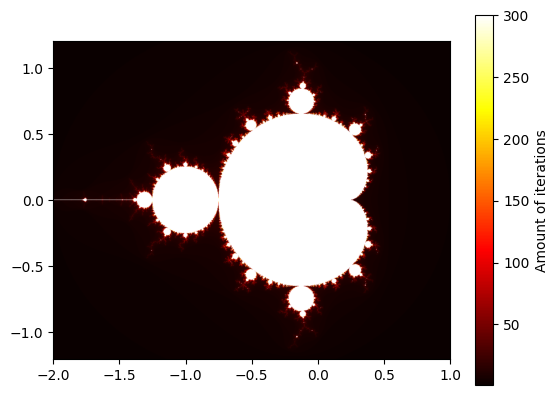

In [10]:
import numpy as np
from numba import cuda
import matplotlib.pyplot as plt

@cuda.jit
def mandelbrot_gpu(out, xmin, xmax, ymin, ymax, max_iter):
    x, y = cuda.grid(2)

    H, W = out.shape

   # TODO 1: перевірка меж — що робить потік, якому не дісталось точки?
    if x >= W or y >= H:
        return

   # TODO 2: координати точки cx, cy
    cx = xmin + x * (xmax - xmin) / W
    cy = ymin + y * (ymax - ymin) / H

    # TODO 3: внутрішній цикл і запис результату в out[y, x]

    zx = 0.0
    zy = 0.0
    iteration = 0

    while zx * zx + zy * zy <= 4.0 and iteration < max_iter:
        zx_new = zx * zx - zy * zy + cx
        zy = 2.0 * zx * zy + cy
        zx = zx_new
        iteration += 1

    out[y, x] = iteration


XMIN, XMAX, YMIN, YMAX = -2.0, 1.0, -1.2, 1.2
MAX_ITER = 300
W, H = 1200, 800

potokiv = (16, 16)

# Количество блоков по x и y
blokiv = (
    (W + potokiv[0] - 1) // potokiv[0],
    (H + potokiv[1] - 1) // potokiv[1]
)

d_out = cuda.device_array((H, W), dtype=np.int32)

mandelbrot_gpu[blokiv, potokiv](
    d_out, XMIN, XMAX, YMIN, YMAX, MAX_ITER
)

cuda.synchronize()
out = d_out.copy_to_host()

#Показ картинки
plt.imshow(
    out,
    extent=[XMIN, XMAX, YMIN, YMAX],
    origin="lower",
    cmap="hot"
)
plt.colorbar(label="Amount of iterations")
plt.show()

In [14]:
from numba import njit, prange
import numpy as np

def mandelbrot_pixel(c: complex, max_iter: int) -> int:
    z = 0j

    for n in range(max_iter):
        if z.real * z.real + z.imag * z.imag > 4.0:
            return n
        z = z * z + c

    return max_iter


def poslidovno():
    pixels = []
    dx = (XMAX - XMIN) / W
    dy = (YMAX - YMIN) / H

    for row in range(H):
        y = YMIN + row * dy
        row_pixels = []

        for col in range(W):
            x = XMIN + col * dx
            row_pixels.append(
                mandelbrot_pixel(complex(x, y), MAX_ITER)
            )

        pixels.append(row_pixels)

    return np.asarray(pixels, dtype=np.int32)

# Отримуємо еталонне зображення
reference_out = poslidovno()

# TODO: скільки точок out відрізняються від еталона?
rozbizhnyh = np.sum(out != reference_out)
print("розбіжних точок:", rozbizhnyh, "з", W * H)

розбіжних точок: 2 з 960000


In [17]:
import time

def zamir_gpu(W, H, blok=(16, 16), n=3):
    host = np.empty((H, W), np.int32)
    bx, by = blok
    blokiv = ((W + bx - 1)//bx, (H + by - 1)//by)
    chasy = []

    for _ in range(n):
        start = time.perf_counter()
        d_out = cuda.to_device(host)
        t_tudy = time.perf_counter() - start

        start = time.perf_counter()
        mandelbrot_gpu[blokiv, blok](d_out, XMIN, XMAX, YMIN, YMAX, MAX_ITER)
        cuda.synchronize()
        t_yadro = time.perf_counter() - start

        start = time.perf_counter()
        out = d_out.copy_to_host()
        t_nazad = time.perf_counter() - start

        chasy.append((t_tudy, t_yadro, t_nazad, out))

    return min(chasy, key=lambda r: sum(r[:3]))


t_tudy, t_yadro, t_nazad, out = zamir_gpu(3000, 2000)

kopiyuvannya = t_tudy + t_nazad
chastka = kopiyuvannya / (kopiyuvannya + t_yadro) * 100

print(f"Туди: {t_tudy*1000:.3f} мс")
print(f"Ядро: {t_yadro*1000:.3f} мс")
print(f"Назад: {t_nazad*1000:.3f} мс")
print(f"Копіювання: {chastka:.2f}%")

Туди: 5.380 мс
Ядро: 56.794 мс
Назад: 11.870 мс
Копіювання: 23.30%
